Data Preparation & Transformation


In [ ]:

# Core data libraries
import numpy as np # numerical operations / ədədi hesablamalar üçün
import pandas as pd # dataframes (for tables) / cədvəl tipli məlumat üçün əsas kitabxana

# Visualization libraries s
import matplotlib.pyplot as plt  # basic plotting / sadə qrafiklər çəkmək
import seaborn as sns # advanced statistical plots / statistik vizuallaşdırma

# Machine learning tools from scikit-learn
from sklearn.model_selection import train_test_split # split data into train/test / məlumatı təlim və test hissələrinə bölmək
from sklearn.compose import ColumnTransformer # apply different transformers to columns / müxtəlif sütunlara fərqli çevrilmələr tətbiq etmək
from sklearn.impute import SimpleImputer # fill missing values / əskik dəyərləri doldurmaq
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
# scaling, encoding

# Statistics and outlier detection tools
from scipy import stats # statistical functions / statistik funksiyalar (məsələn, z-score)

# Random seed for reproducibility (ensures same results each run)
RANDOM_STATE = 42  # eyni nəticə üçün sabit təsadüfi başlanğıc

# Plot appearance settings
plt.rcParams['figure.figsize'] = (10,5) # default figure size / qrafik ölçüsü
plt.rcParams['font.size'] = 12 # font size / şrift ölçüsü --- runtime configuration

In [32]:
# Try loading the Titanic dataset
try:
    import seaborn as sns
    df = sns.load_dataset("titanic")  # load dataset directly from seaborn library
    source_note = "seaborn.titanic"
except Exception:
    # If seaborn or dataset not available, create a small manual example.
    data = {
        "age": [22, 38, 26, None, 35, 54, 2, 27, 14, 58],
        "fare": [7.25, 71.83, 7.92, 53.1, 8.05, 51.86, 21.08, 11.13, 30.07, 263.0],
        "sex": ["male", "female", "female", "female", "male", "male", "male", "female", "male", "female"],
        "class": ["Third", "First", "Third", "First", "Third", "First", "Second", "Third", "Second", "First"],
        "embarked": ["S", "C", "S", "S", "S", "C", "S", None, "C", "S"],
        "survived": [0, 1, 1, 1, 0, 0, 1, 1, 0, 0],
    }
    df = pd.DataFrame(data)
    source_note = "synthetic_fallback"

In [33]:
# df = pd.read_csv("titanic.csv") # load dataset from local CSV file

In [34]:
# Show where data comes from and how many rows/columns it has
print("Data source:", source_note)
print("Shape (rows, columns):", df.shape)

Data source: seaborn.titanic
Shape (rows, columns): (891, 15)


In [35]:
# View the first few rows — always a good first step in EDA
print("First 10 rows of the dataset / Datasetin ilk 10 sətri:")
display(df.head(10))

First 10 rows of the dataset / Datasetin ilk 10 sətri:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [36]:
# Get information about column types and missing values
print("--- Info ---")
df.info()  # shows column names, types, non-null counts

--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [37]:
# Summary statistics for numeric columns (mean, std, quartiles, etc.)
print("--- Describe (numeric columns) ---")
display(df.describe().T)

--- Describe (numeric columns) ---


,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [38]:
# Check value counts for categorical columns
for column in df.select_dtypes(include=["object", "category"]).columns:
    print("\nColumn name:", column) # print column name 
    print(df[column].value_counts(dropna=False)) # show how many times each value appears


Column name: sex
sex
male      577
female    314
Name: count, dtype: int64

Column name: embarked
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Column name: class
class
Third     491
First     216
Second    184
Name: count, dtype: int64

Column name: who
who
man      537
woman    271
child     83
Name: count, dtype: int64

Column name: deck
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64

Column name: embark_town
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

Column name: alive
alive
no     549
yes    342
Name: count, dtype: int64


In [39]:
# Show all rows and columns
pd.set_option('display.max_rows', None)       # show all rows
pd.set_option('display.max_columns', None)    # show all columns
pd.set_option('display.width', 1000)          # wider output
pd.set_option('display.max_colwidth', None)   # don't truncate column content


In [40]:
for column in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\nColumn: {column}")
    display(df[column].value_counts(dropna=False).to_frame('count'))  # use display() in notebooks



Column: sex


,count
sex,
male,577
female,314



Column: embarked


,count
embarked,
S,644
C,168
Q,77
NaN,2



Column: class


...

,count
deck,
NaN,688
C,59
B,47
D,33
E,32
A,15
F,13
G,4



Column: embark_town


,count
embark_town,
Southampton,644
Cherbourg,168
Queenstown,77
NaN,2



Column: alive


,count
alive,
no,549
yes,342


In [41]:
# Missing values per column
print("Missing values per column:")
display(df.isna().sum())


Missing values per column:


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [42]:
# Numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("\nNumeric columns detected:", numeric_cols)


Numeric columns detected: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


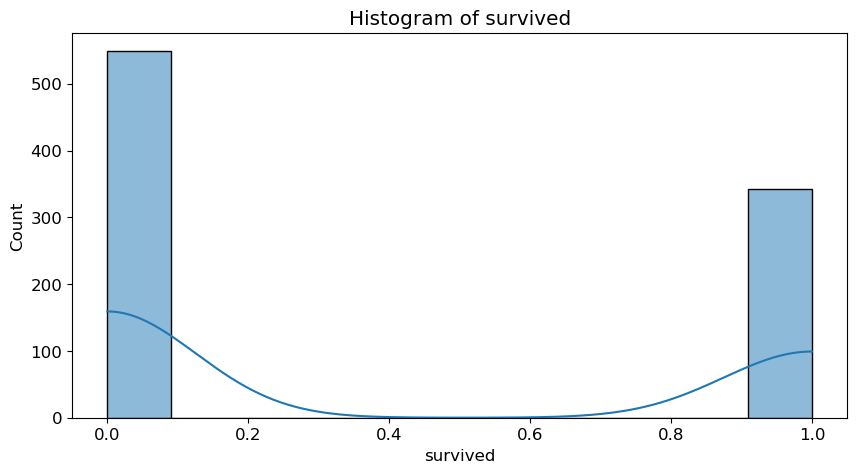

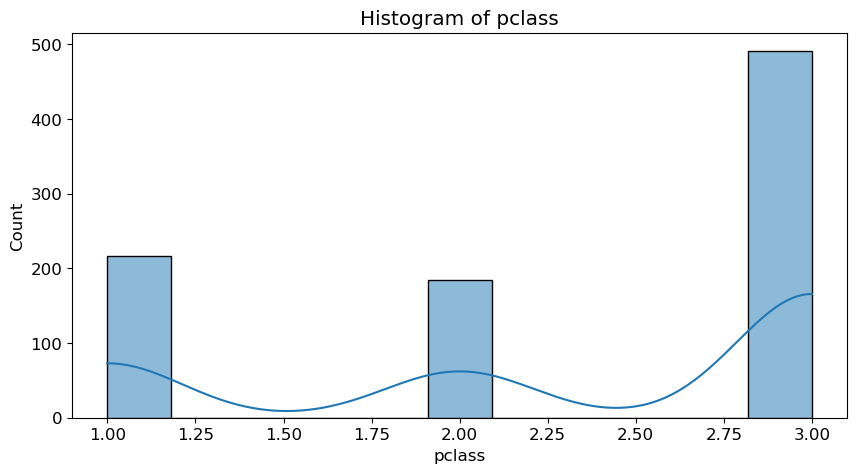

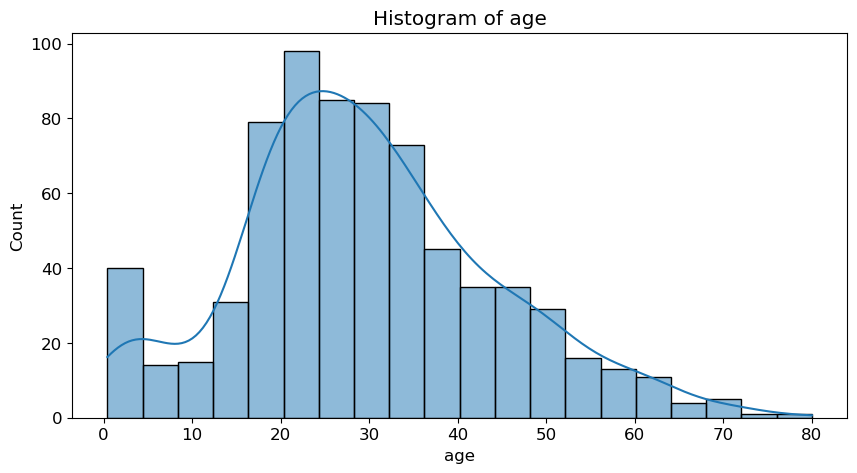

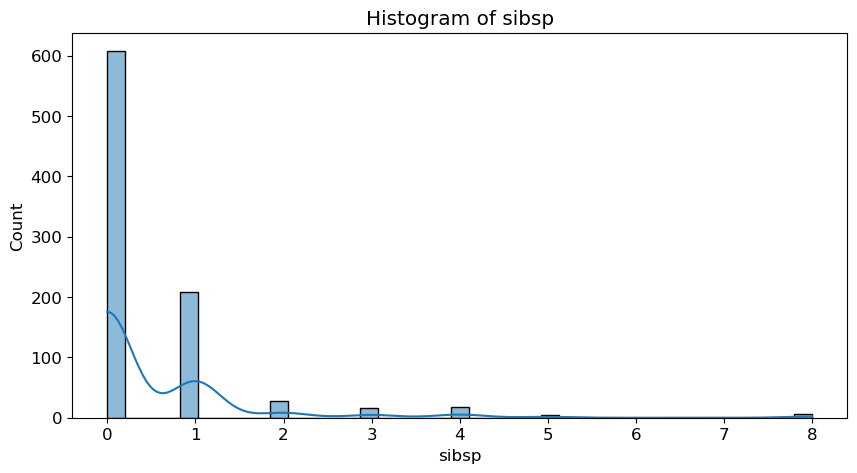

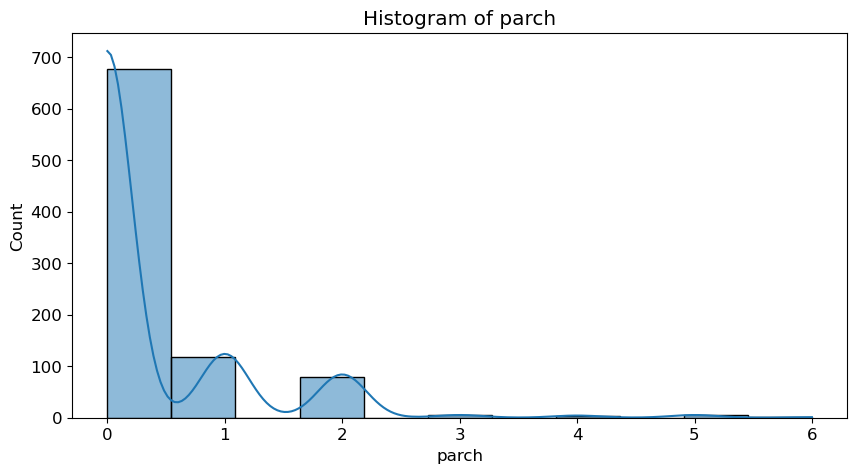

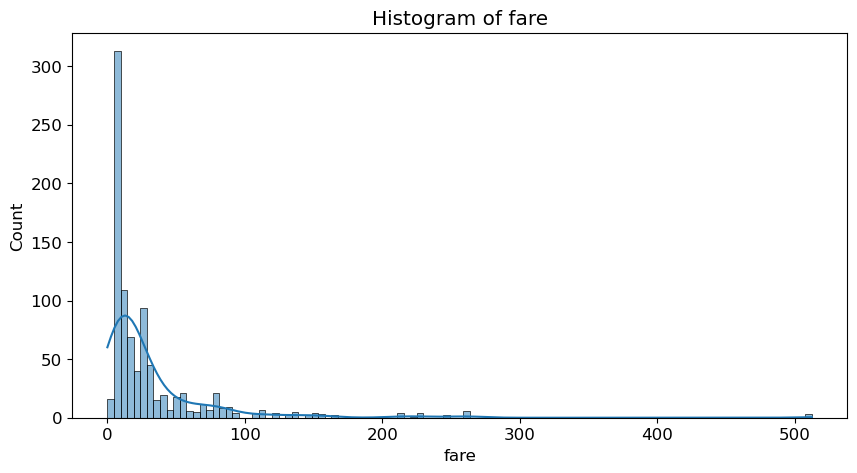

In [43]:
# Plot histograms for numeric columns
for col in numeric_cols:
    plt.figure()
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    if 'sns' in globals():  # check if seaborn is available
        sns.histplot(df[col].dropna(), kde=True)
    else:
        plt.hist(df[col].dropna(), bins=20)
    plt.show()

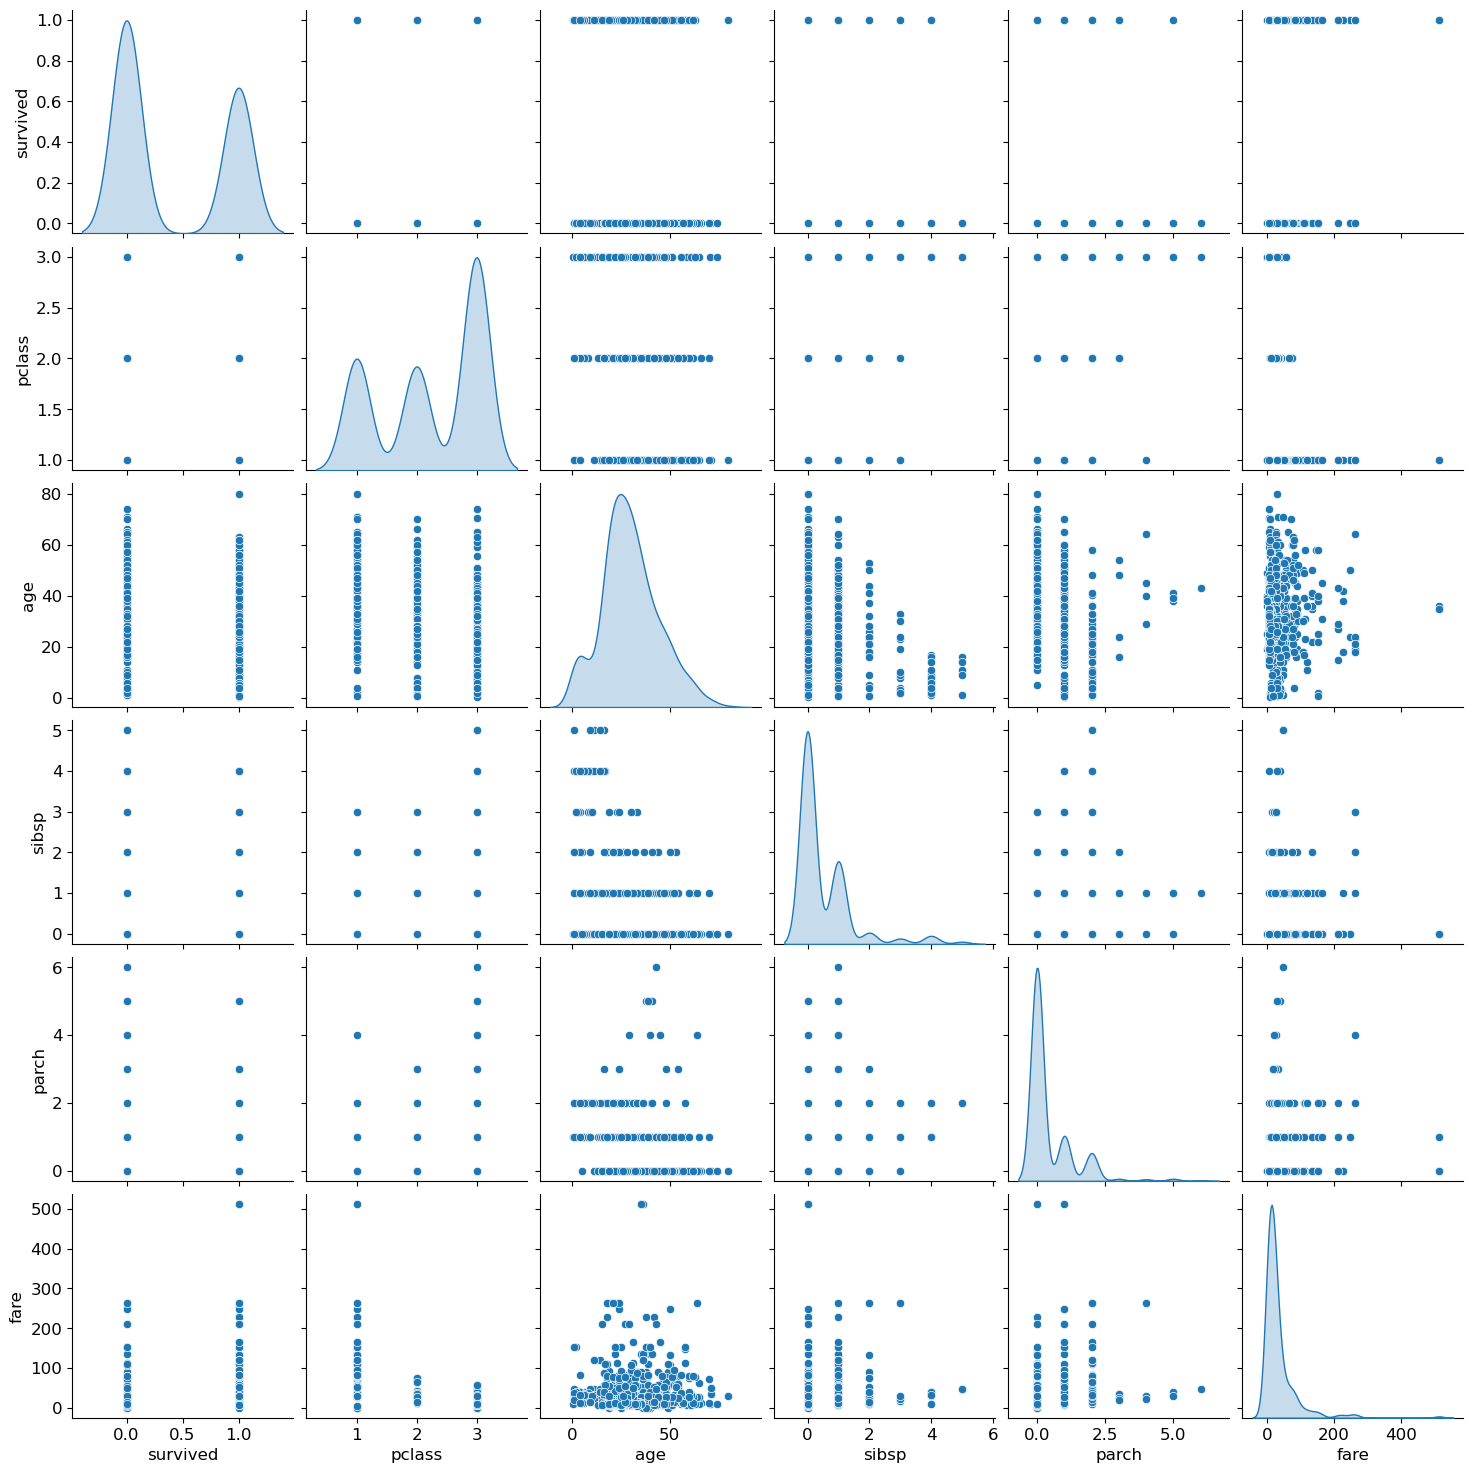

In [44]:
# import seaborn as sns
# Only include numeric columns
sns.pairplot(df[numeric_cols].dropna(), diag_kind='kde')
plt.show()


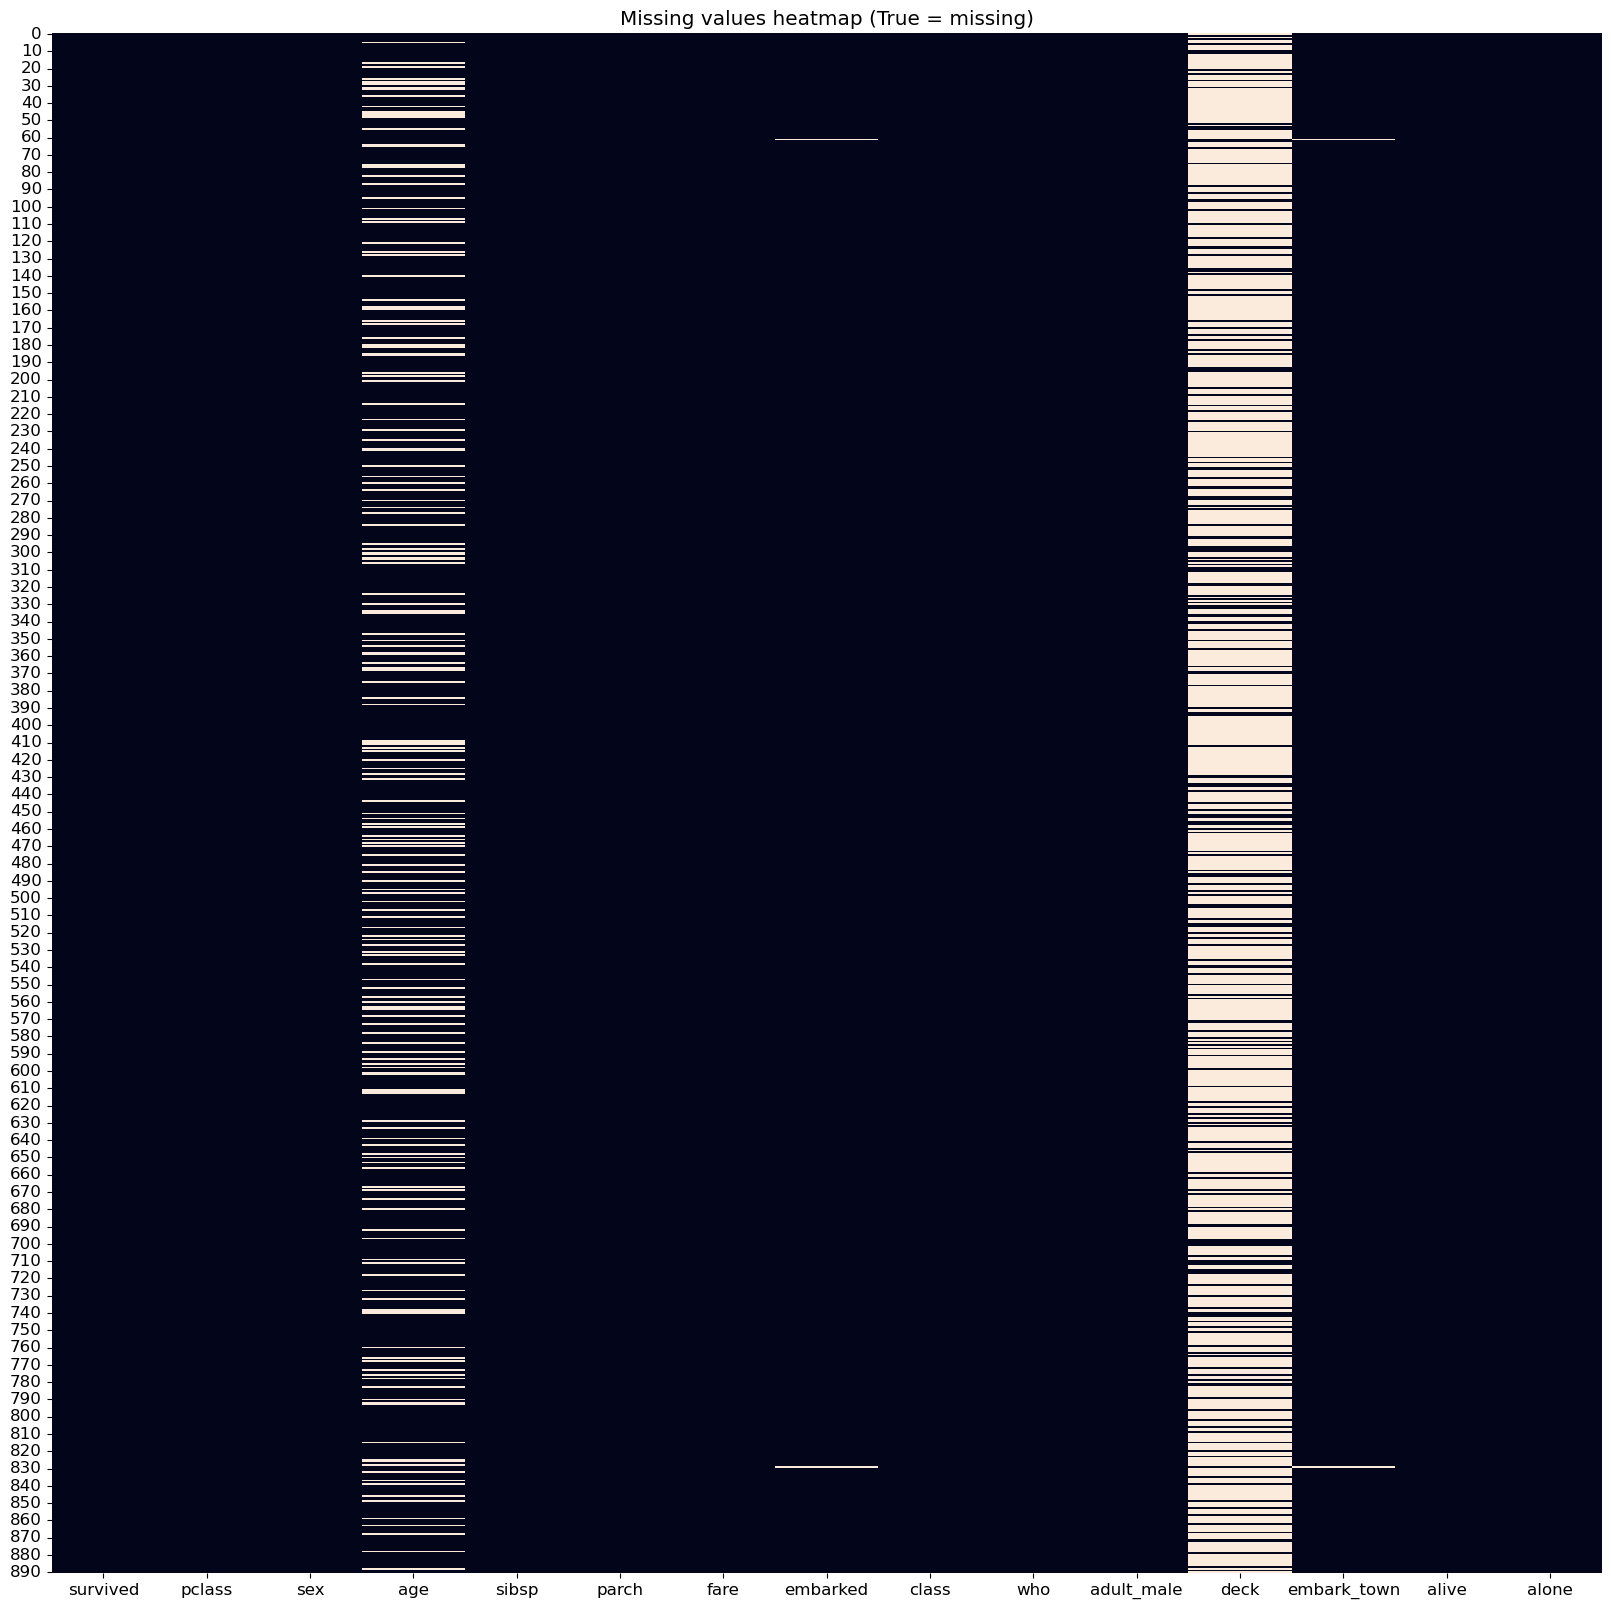

In [45]:
# Missingness heatmap
if 'sns' in globals():
    plt.figure(figsize=(20, 20))
    sns.heatmap(df.isna(), cbar=False)
    plt.title("Missing values heatmap (True = missing)")
    plt.show()
else:
    print("Seaborn not available — skipping missingness heatmap.")


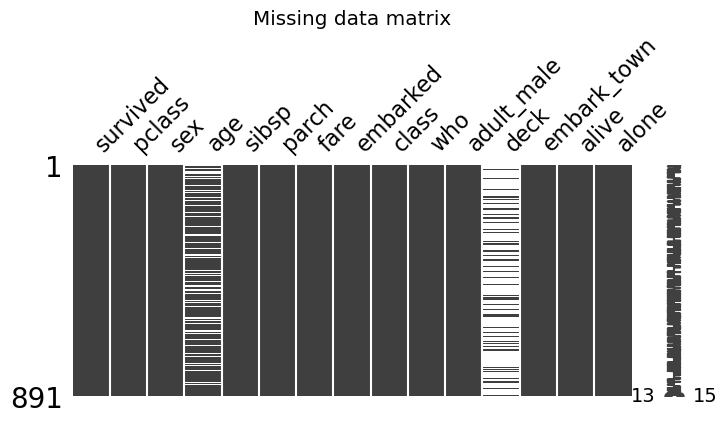

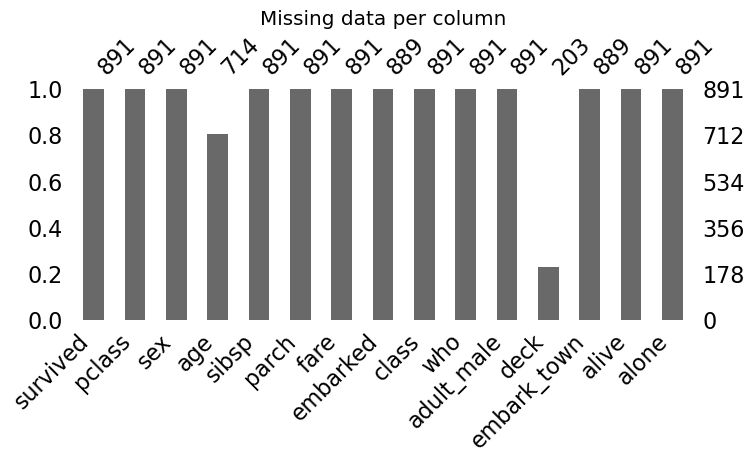

In [46]:
try:
    import missingno as msno

    # Matrix plot (shows missing vs present)
    msno.matrix(df, figsize=(8, 3))
    plt.title("Missing data matrix")
    plt.show()

    # Bar plot (counts of missing values per column)
    msno.bar(df, figsize=(8, 3))
    plt.title("Missing data per column")
    plt.show()

except ImportError:
    print("missingno not installed — skipping advanced missingness plots.")

In [49]:
# Detect outliers using IQR and Z-score

#  Functions to detect outliers

def detect_outliers_iqr(series, k=1.5):
    """Return boolean mask marking outliers using IQR."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (series < lower) | (series > upper)

def detect_outliers_zscore(series, thresh=3.0):
    """Return boolean mask marking outliers using z-score."""
    z = np.abs(stats.zscore(series.dropna()))
    mask = pd.Series(False, index=series.index)
    mask.loc[series.dropna().index] = z > thresh
    return mask


# Numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("\nNumeric columns detected:", numeric_cols)


# Apply outlier detection
outlier_report = {}
for col in numeric_cols:
    if df[col].dropna().shape[0] < 2:
        continue
    outlier_report[col] = {
        'iqr_count': int(detect_outliers_iqr(df[col]).sum()),
        'zscore_count': int(detect_outliers_zscore(df[col]).sum())
    }

print("Outlier summary (counts per column):")
display(pd.DataFrame(outlier_report).T)




Numeric columns detected: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Outlier summary (counts per column):


,iqr_count,zscore_count
survived,0,0
pclass,0,0
age,11,2
sibsp,46,30
parch,213,15
fare,116,20



Numeric columns detected: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


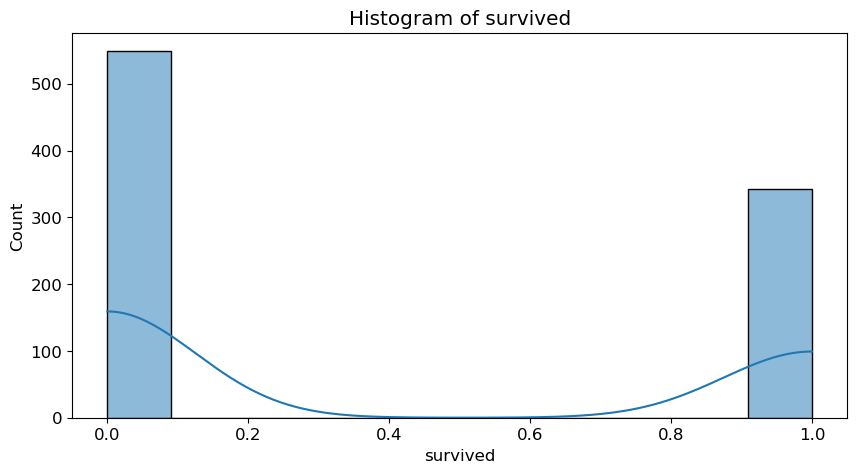

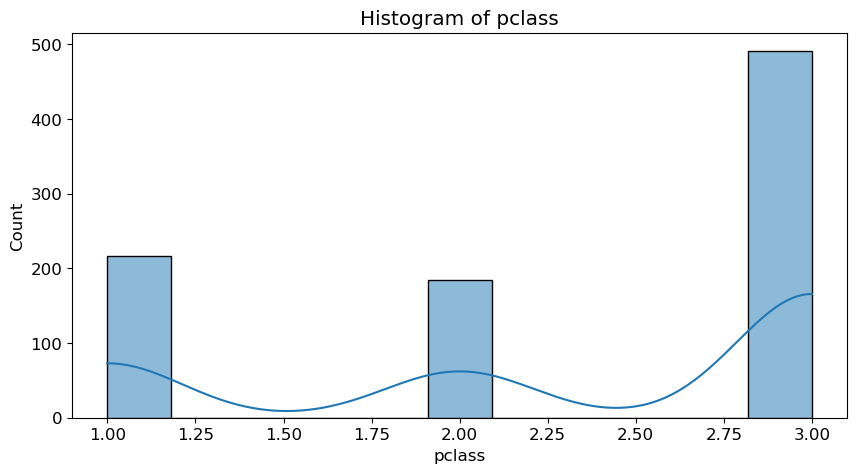

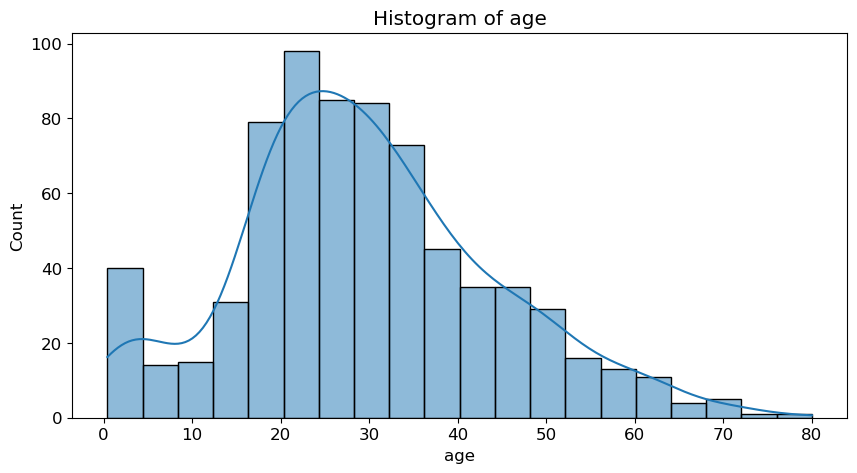

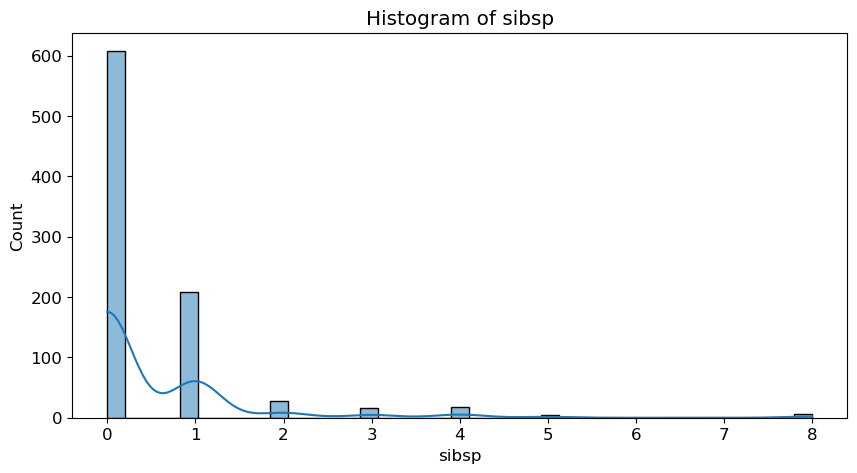

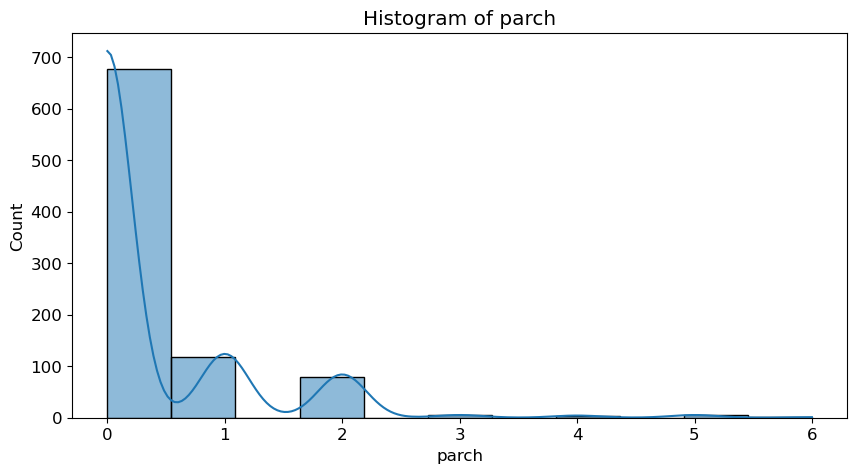

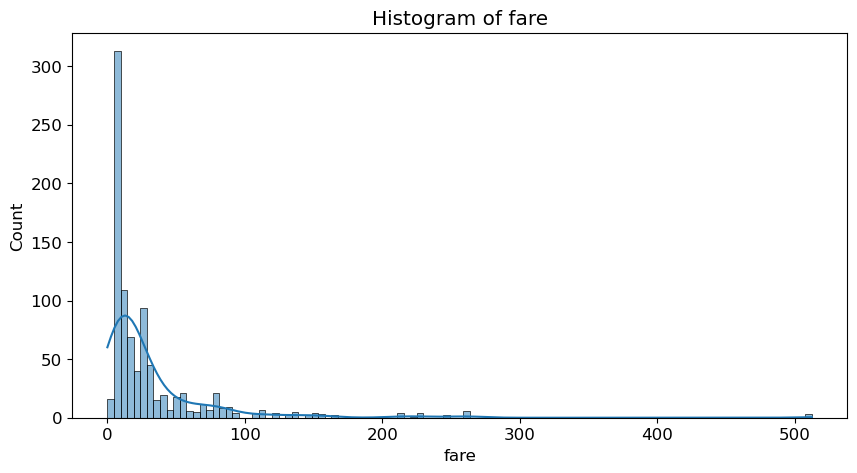

In [18]:
# Plot histograms for numeric columns

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("\nNumeric columns detected:", numeric_cols)

for col in numeric_cols:
    plt.figure()
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    if 'sns' in globals():  # check if seaborn is available
        sns.histplot(df[col].dropna(), kde=True)
    else:
        plt.hist(df[col].dropna(), bins=20)
    plt.show()

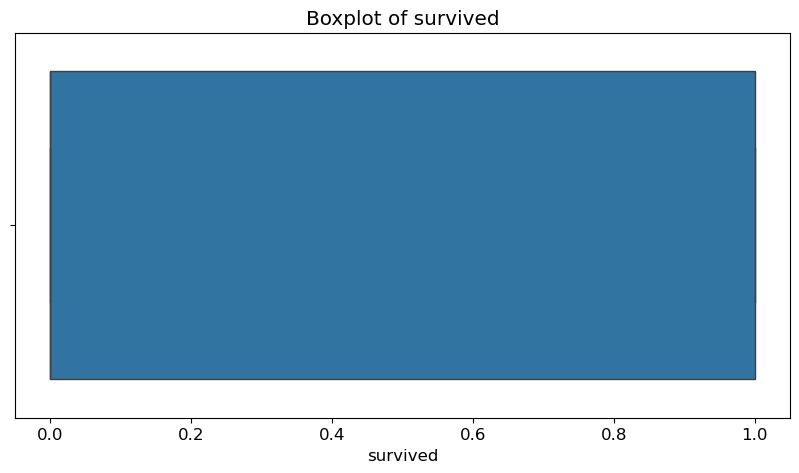

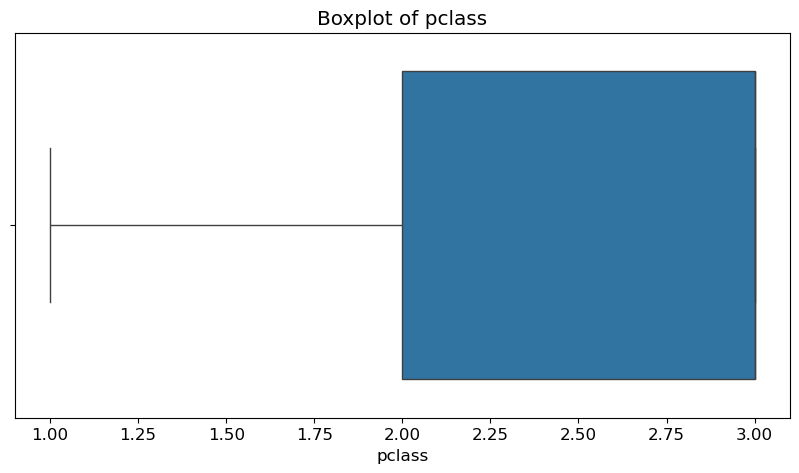

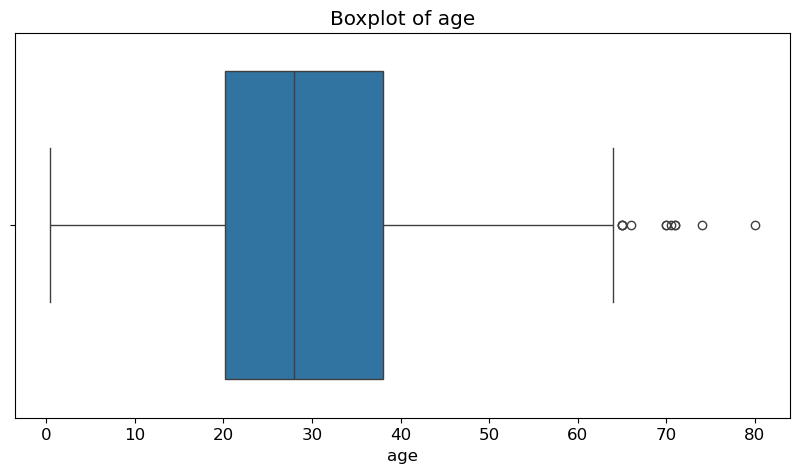

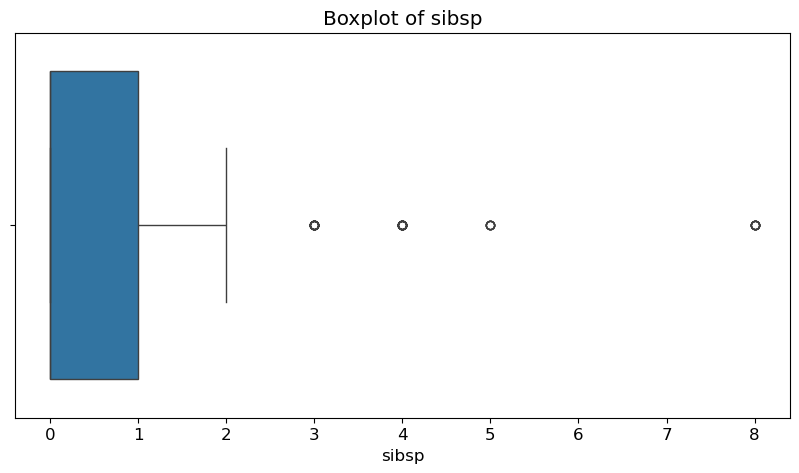

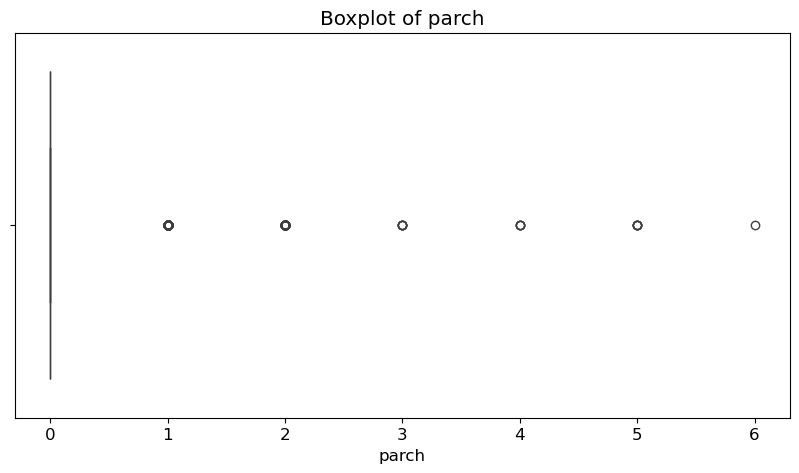

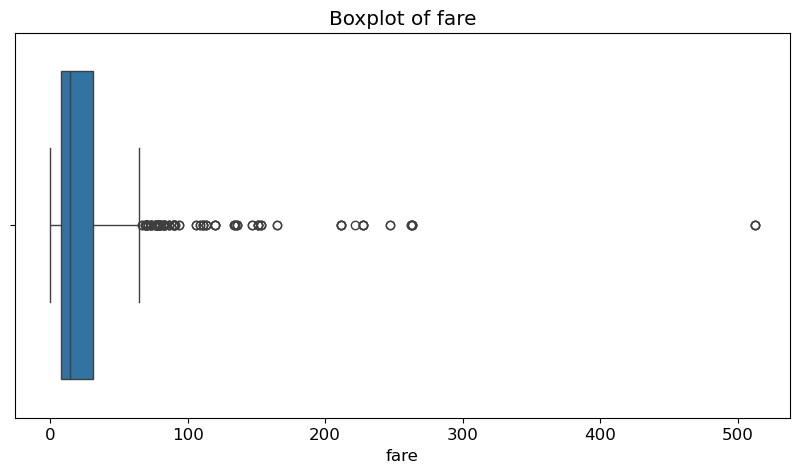

In [19]:
# boxplot
for col in numeric_cols:
    plt.figure()
    plt.title(f"Boxplot of {col}")
    if 'sns' in globals():
        sns.boxplot(x=df[col])
    else:
        plt.boxplot(df[col].dropna())
        plt.xlabel(col)
    plt.show()

In [20]:
# Copy dataframe
df_imputed = df.copy()

In [ ]:
# df['Age'].fillna(df['Age'].median(), inplace=True)


In [21]:
# Numeric: fill missing 'age' with median
if 'age' in df_imputed.columns:
    median_age = df_imputed['age'].median()
    print(f"Median age: {median_age}")
    df_imputed['age'] = df_imputed['age'].fillna(median_age)

Median age: 28.0


In [22]:
# Categorical: fill missing 'embarked' with mode
if 'embarked' in df_imputed.columns:
    mode_embarked = df_imputed['embarked'].mode()[0]
    print(f"Most frequent embarkation: {mode_embarked}")
    df_imputed['embarked'] = df_imputed['embarked'].fillna(mode_embarked)

print("Missing values handled (simple method).")
display(df_imputed.head())

Most frequent embarkation: S
Missing values handled (simple method).


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [23]:
# Select numeric and categorical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numeric columns:", num_cols)
print("\nCategorical columns:", cat_cols)

Numeric columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical columns: ['sex', 'embarked', 'class', 'who', 'deck', 'embark_town', 'alive']


In [24]:

num_imputer = SimpleImputer(strategy='mean')
cat_imputer = SimpleImputer(strategy='most_frequent')

# Combine imputers in a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_imputer, num_cols),
        ('cat', cat_imputer, cat_cols)
    ],
    remainder='passthrough'
)

# Fit and transform
imputed_array = preprocessor.fit_transform(df)
output_cols = num_cols + cat_cols + [c for c in df.columns if c not in num_cols + cat_cols]

if len(output_cols) != imputed_array.shape[1]:
    output_cols = [f"col_{i}" for i in range(imputed_array.shape[1])]

df_final = pd.DataFrame(imputed_array, columns=output_cols)

print("\nAfter sklearn SimpleImputer:")
display(df_final.head(20))

print("\nRemaining missing values (should be 0):")
display(df_final.isna().sum())



After sklearn SimpleImputer:


,survived,pclass,age,sibsp,parch,fare,sex,embarked,class,who,deck,embark_town,alive,adult_male,alone
0,0.0,3.0,22.0,1.0,0.0,7.25,male,S,Third,man,C,Southampton,no,True,False
1,1.0,1.0,38.0,1.0,0.0,71.2833,female,C,First,woman,C,Cherbourg,yes,False,False
2,1.0,3.0,26.0,0.0,0.0,7.925,female,S,Third,woman,C,Southampton,yes,False,True
3,1.0,1.0,35.0,1.0,0.0,53.1,female,S,First,woman,C,Southampton,yes,False,False
4,0.0,3.0,35.0,0.0,0.0,8.05,male,S,Third,man,C,Southampton,no,True,True
5,0.0,3.0,29.699118,0.0,0.0,8.4583,male,Q,Third,man,C,Queenstown,no,True,True
6,0.0,1.0,54.0,0.0,0.0,51.8625,male,S,First,man,E,Southampton,no,True,True
7,0.0,3.0,2.0,3.0,1.0,21.075,male,S,Third,child,C,Southampton,no,False,False
8,1.0,3.0,27.0,0.0,2.0,11.1333,female,S,Third,woman,C,Southampton,yes,False,False
9,1.0,2.0,14.0,1.0,0.0,30.0708,female,C,Second,child,C,Cherbourg,yes,False,False



Remaining missing values (should be 0):


survived       0
pclass         0
age            0
sibsp          0
parch          0
fare           0
sex            0
embarked       0
class          0
who            0
deck           0
embark_town    0
alive          0
adult_male     0
alone          0
dtype: int64

In [25]:
# Copy dataframe for encoding demonstration
df_enc = df.copy()

In [26]:
# Ordinal encoding example: 'class' (First > Second > Third)
if 'class' in df_enc.columns:
    class_order = ['Third', 'Second', 'First']  # define order
    df_enc['class'] = pd.Categorical(df_enc['class'], categories=class_order, ordered=True)

    ord_enc = OrdinalEncoder(categories=[class_order])
    df_enc['class_ordinal'] = ord_enc.fit_transform(df_enc[['class']]).astype(float)
    print("Ordinal encoding for 'class' (Third=0, Second=1, First=2):")
    display(df_enc[['class', 'class_ordinal']].head(20))

Ordinal encoding for 'class' (Third=0, Second=1, First=2):


,class,class_ordinal
0,Third,0.0
1,First,2.0
2,Third,0.0
3,First,2.0
4,Third,0.0
5,Third,0.0
6,First,2.0
7,Third,0.0
8,Third,0.0
9,Second,1.0


In [ ]:
# OneHot encoding example: 'sex' (male/female)
if 'sex' in df_enc.columns:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')  # updated param name
    sex_trans = ohe.fit_transform(df_enc[['sex']].fillna('missing'))
    sex_cols = ohe.get_feature_names_out(['sex'])
    df_sex_ohe = pd.DataFrame(sex_trans, columns=sex_cols, index=df_enc.index)

    print("OneHot encoding for 'sex':", list(sex_cols))
    display(df_sex_ohe.head())

OneHot encoding for 'sex': ['sex_female', 'sex_male']


,sex_female,sex_male
0,0.0,1.0
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0
4,0.0,1.0


Numeric columns used for scaling demo: ['pclass', 'age', 'sibsp', 'parch', 'fare']

Scaler: StandardScaler (mean=0, std=1)


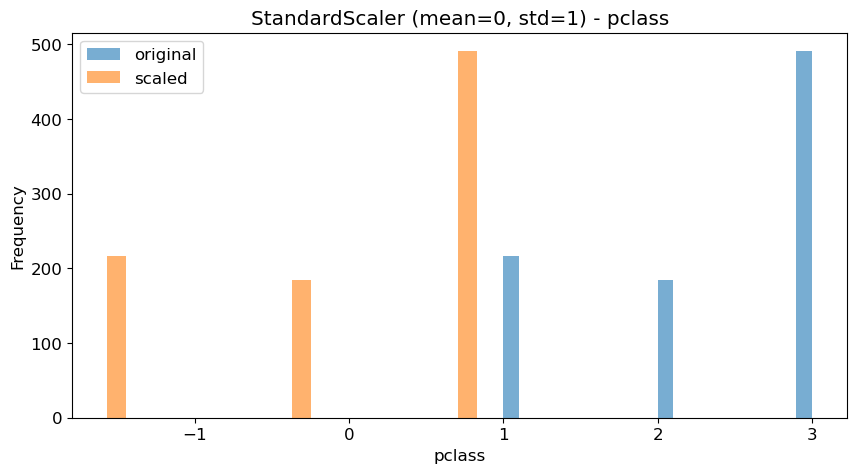

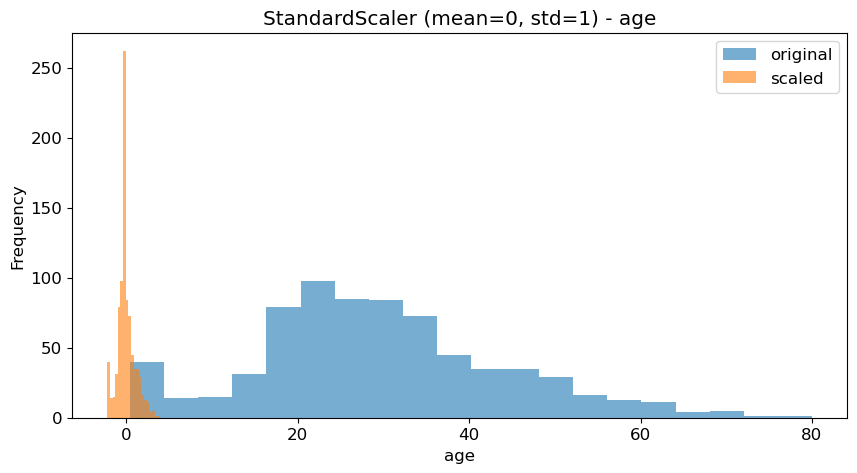

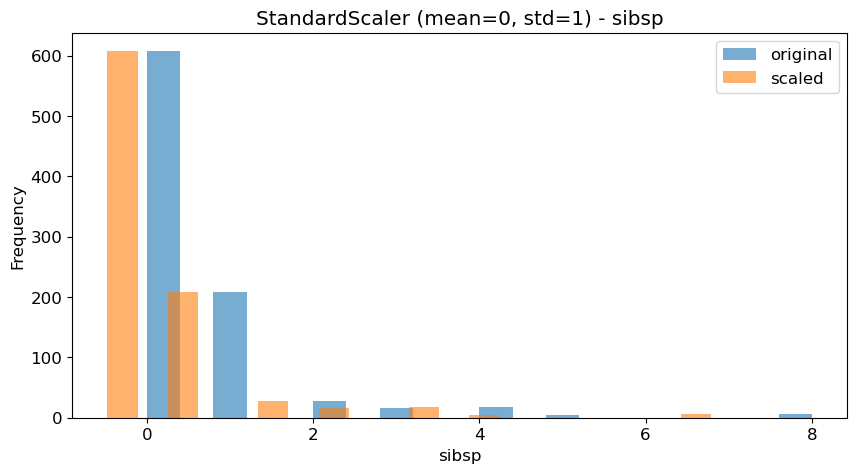

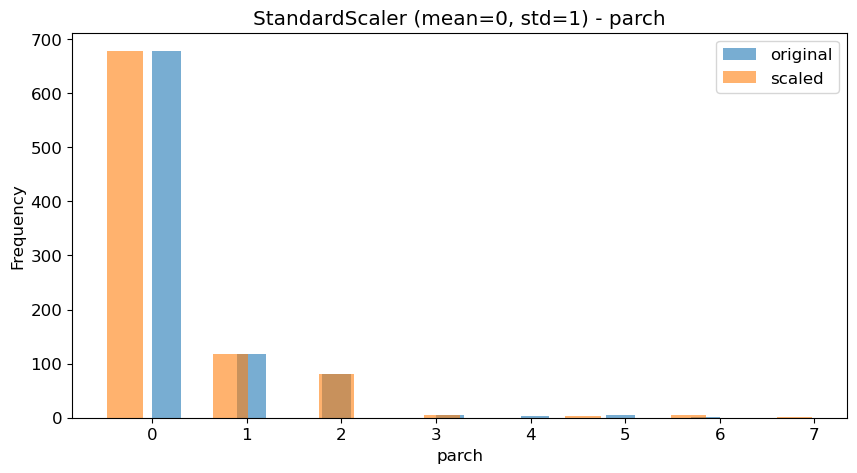

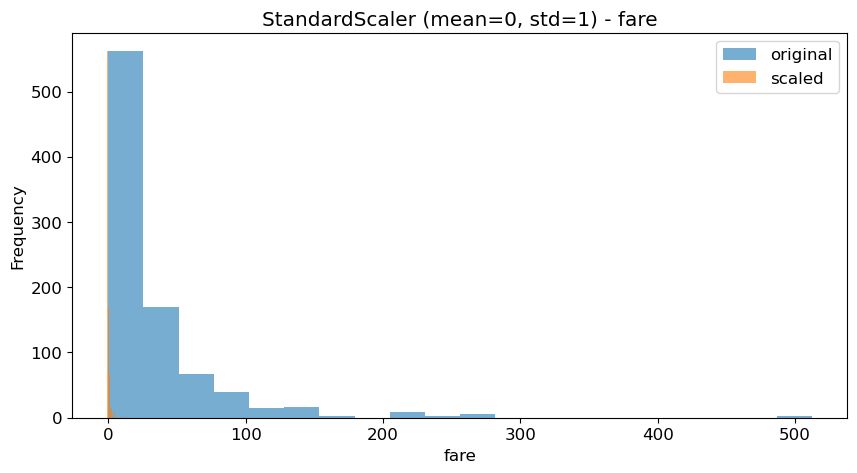


Scaler: MinMaxScaler (scaled to 0-1)


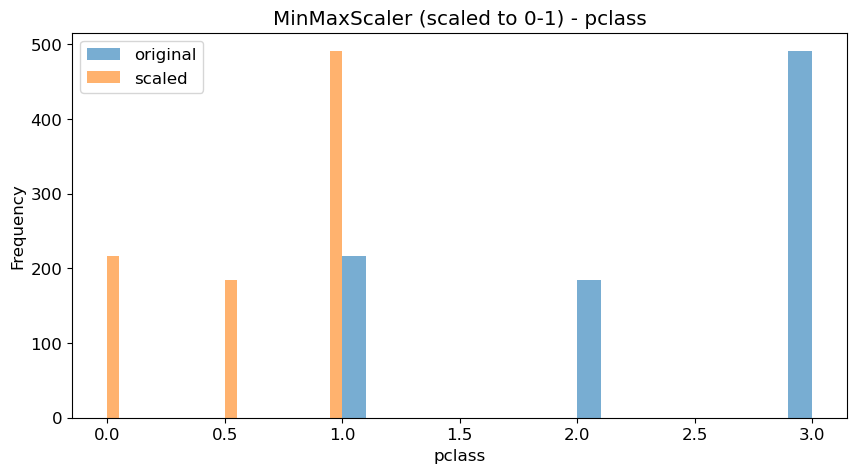

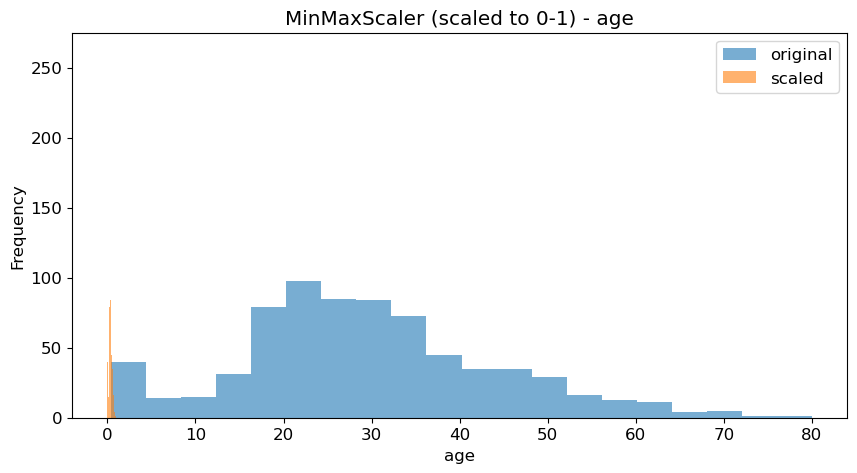

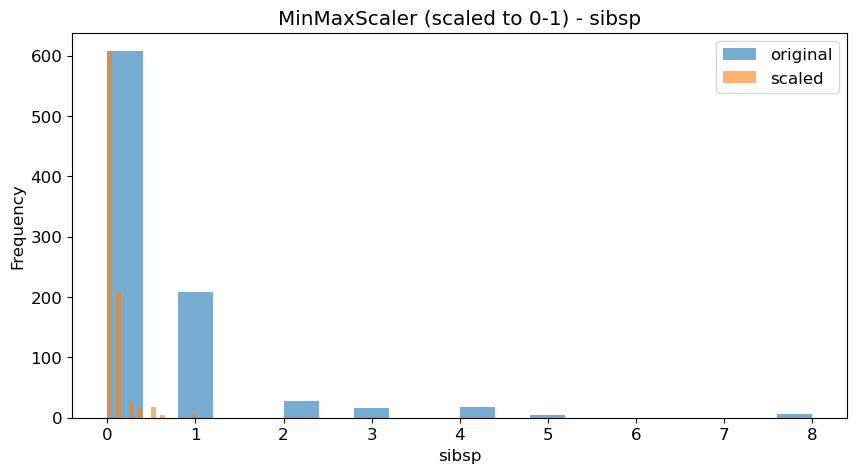

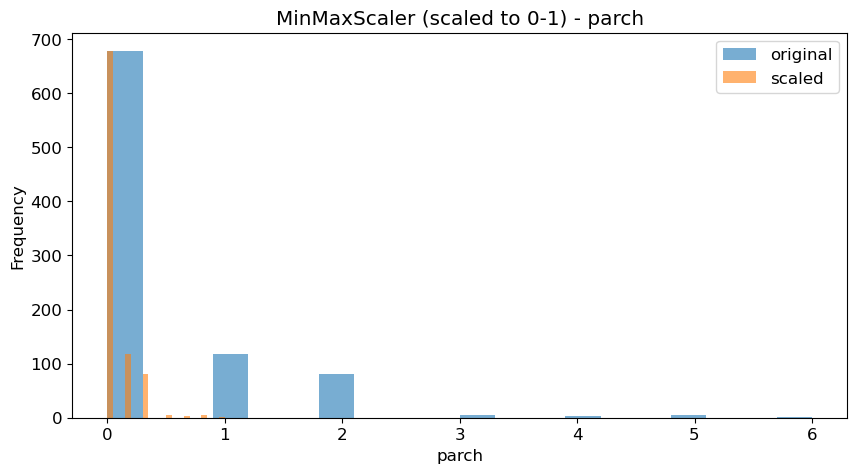

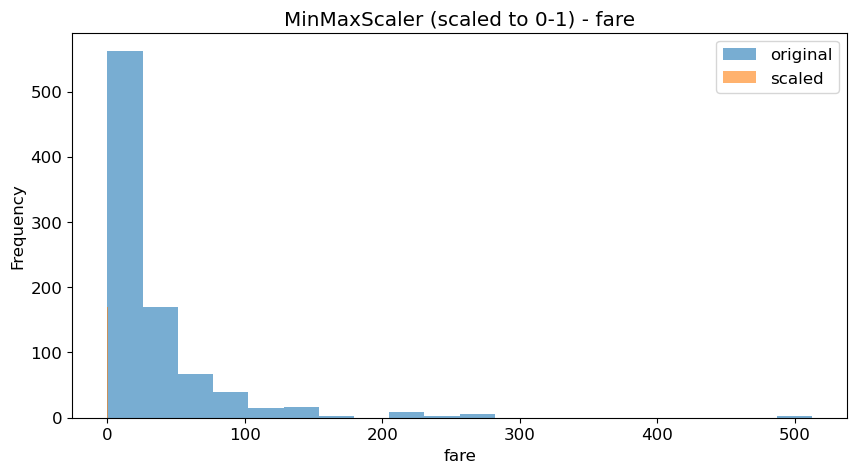

In [28]:

# Select numeric columns (exclude target 'survived')
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'survived']
print("Numeric columns used for scaling demo:", numeric_cols)

# Prepare a small DataFrame for plotting
demo_df = df[numeric_cols].copy()

# Function to plot histograms before/after scaling
def plot_scaler(transformer, name):
    print(f"\nScaler: {name}")
    # Fit-transform, filling NaNs with median
    transformed = transformer.fit_transform(demo_df.fillna(demo_df.median()))
    transformed_df = pd.DataFrame(transformed, columns=numeric_cols)
    
    # Plot original vs transformed
    for col in numeric_cols:
        plt.figure()
        plt.title(f"{name} - {col}")
        plt.hist(demo_df[col].dropna(), bins=20, alpha=0.6, label='original')
        plt.hist(transformed_df[col].dropna(), bins=20, alpha=0.6, label='scaled')
        plt.xlabel(col)
        plt.ylabel('Frequency')
        plt.legend()
        plt.show()

#  StandardScaler
plot_scaler(StandardScaler(), "StandardScaler (mean=0, std=1)")

# MinMaxScaler
plot_scaler(MinMaxScaler(), "MinMaxScaler (scaled to 0-1)")

